## **Data Exploration and Preprocessing**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler

In [ ]:
df = pd.read_excel("/content/bank-full.xlsx")

In [ ]:
df.head(5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
df.drop(['month','day','duration'], axis=1, inplace=True)

In [ ]:
df.shape

(45211, 14)

In [ ]:
banking_income_map = {    'management': 'High', 'entrepreneur': 'High', 'self-employed': 'High',    'technician': 'Mid', 'admin.': 'Mid', 'services': 'Mid', 'retired': 'Mid',    'blue-collar': 'Low', 'housemaid': 'Low', 'student': 'Low', 'unknown': 'Low' }
df['income_group'] = df['job'].map(banking_income_map)
print(df[['job', 'income_group']])

                job income_group
0        management         High
1        technician          Mid
2      entrepreneur         High
3       blue-collar          Low
4           unknown          Low
...             ...          ...
45206    technician          Mid
45207       retired          Mid
45208       retired          Mid
45209   blue-collar          Low
45210  entrepreneur         High

[45211 rows x 2 columns]


In [ ]:
df.drop(['job'], axis=1, inplace=True)

In [ ]:
df.head()


,age,marital,education,default,balance,housing,loan,contact,campaign,pdays,previous,poutcome,y,income_group
0,58,married,tertiary,no,2143,yes,no,unknown,1,-1,0,unknown,no,High
1,44,single,secondary,no,29,yes,no,unknown,1,-1,0,unknown,no,Mid
2,33,married,secondary,no,2,yes,yes,unknown,1,-1,0,unknown,no,High
3,47,married,unknown,no,1506,yes,no,unknown,1,-1,0,unknown,no,Low
4,33,single,unknown,no,1,no,no,unknown,1,-1,0,unknown,no,Low


In [ ]:
df['y'].value_counts()

,count
y,
no,39922
yes,5289


In [ ]:
df['campaign'].unique()

array([ 1,  2,  3,  5,  4,  6,  7,  8,  9, 10, 11, 12, 13, 19, 14, 24, 16,
       32, 18, 22, 15, 17, 25, 21, 43, 51, 63, 41, 26, 28, 55, 50, 38, 23,
       20, 29, 31, 37, 30, 46, 27, 58, 33, 35, 34, 36, 39, 44])

In [ ]:
df['education'].unique()

array(['tertiary', 'secondary', 'unknown', 'primary'], dtype=object)

In [ ]:
print(df.columns)

Index(['age', 'marital', 'education', 'default', 'balance', 'housing', 'loan',
       'contact', 'campaign', 'pdays', 'previous', 'poutcome', 'y',
       'income_group'],
      dtype='object')


In [ ]:
df['income_group'].unique()

array(['High', 'Mid', 'Low', nan], dtype=object)

In [ ]:
df['income_group'].isnull().sum()

np.int64(1303)

In [ ]:
df = df.dropna(subset=['income_group'])

In [ ]:
df['income_group'].isnull().sum()

np.int64(0)

In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43908 entries, 0 to 45210
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   age           43908 non-null  int64 
 1   marital       43908 non-null  object
 2   education     43908 non-null  object
 3   default       43908 non-null  object
 4   balance       43908 non-null  int64 
 5   housing       43908 non-null  object
 6   loan          43908 non-null  object
 7   contact       43908 non-null  object
 8   campaign      43908 non-null  int64 
 9   pdays         43908 non-null  int64 
 10  previous      43908 non-null  int64 
 11  poutcome      43908 non-null  object
 12  y             43908 non-null  object
 13  income_group  43908 non-null  object
dtypes: int64(5), object(9)
memory usage: 5.0+ MB


In [ ]:
print(df["y"].value_counts())

y
no     38821
yes     5087
Name: count, dtype: int64


In [ ]:
print(df["y"].value_counts(normalize=True) * 100)

y
no     88.414412
yes    11.585588
Name: proportion, dtype: float64


In [ ]:
df["contact"].unique()

array(['unknown', 'cellular', 'telephone'], dtype=object)

In [ ]:
df_encoded = df.copy()

binary_cols = ['default', 'housing', 'loan', 'y']
for col in binary_cols:
    df_encoded[col] = df_encoded[col].map({
        'yes': 1,
        'no': 0
    })

categorical_cols = [
    'income_group',
    'marital',
    'education',
    'contact',
    'poutcome'
]

df_encoded = pd.get_dummies(
    df_encoded,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)



In [ ]:
df_encoded.head()

,age,default,balance,housing,loan,campaign,pdays,previous,y,income_group_Low,...,marital_married,marital_single,education_secondary,education_tertiary,education_unknown,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,1,-1,0,0,0,...,1,0,0,1,0,0,1,0,0,1
1,44,0,29,1,0,1,-1,0,0,0,...,0,1,1,0,0,0,1,0,0,1
2,33,0,2,1,1,1,-1,0,0,0,...,1,0,1,0,0,0,1,0,0,1
3,47,0,1506,1,0,1,-1,0,0,1,...,1,0,0,0,1,0,1,0,0,1
4,33,0,1,0,0,1,-1,0,0,1,...,0,1,0,0,1,0,1,0,0,1


In [ ]:
df_encoded.columns

Index(['age', 'default', 'balance', 'housing', 'loan', 'campaign', 'pdays',
       'previous', 'y', 'income_group_Low', 'income_group_Mid',
       'marital_married', 'marital_single', 'education_secondary',
       'education_tertiary', 'education_unknown', 'contact_telephone',
       'contact_unknown', 'poutcome_other', 'poutcome_success',
       'poutcome_unknown'],
      dtype='object')

In [ ]:
df['income_group'].unique()

array(['High', 'Mid', 'Low'], dtype=object)

In [ ]:
df['income_group'].head()

,income_group
0,High
1,Mid
2,High
3,Low
4,Low


## **EDA**

In [ ]:
categorical_cols = [
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "poutcome",
    "income_group"
]

In [ ]:
numerical_cols = [
    "age",
    "balance",
    "campaign",
    "pdays",
    "previous"
]

In [ ]:
df[numerical_cols].describe()

,age,balance,campaign,pdays,previous
count,43908.000000,43908.000000,43908.000000,43908.000000,43908.000000
mean,40.935456,1357.539560,2.773686,40.377403,0.583698
std,10.642826,3041.660282,3.110239,100.288300,2.322249
min,18.000000,-8019.000000,1.000000,-1.000000,0.000000
25%,33.000000,71.000000,1.000000,-1.000000,0.000000
50%,39.000000,446.000000,2.000000,-1.000000,0.000000
75%,48.000000,1423.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,63.000000,854.000000,275.000000


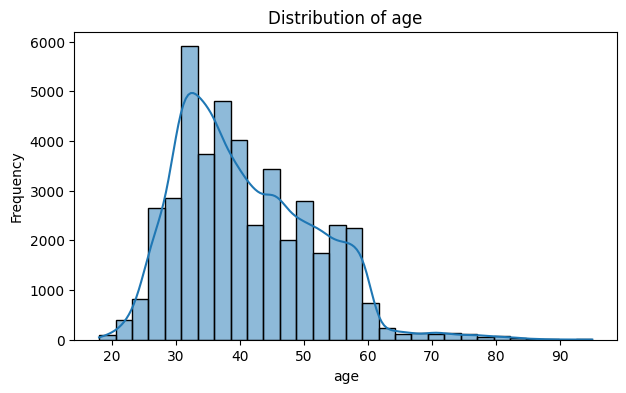

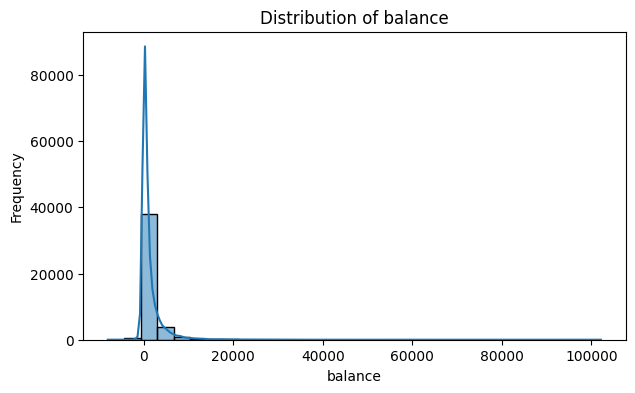

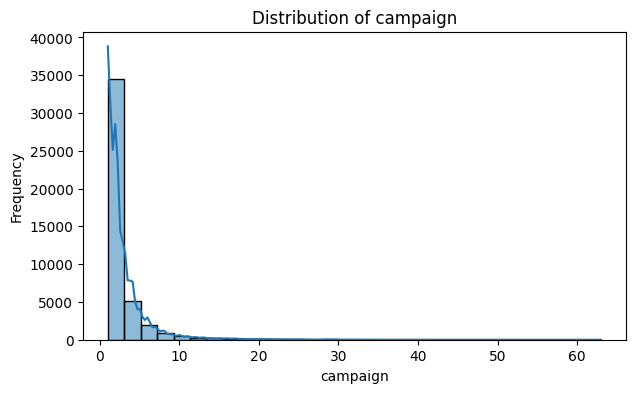

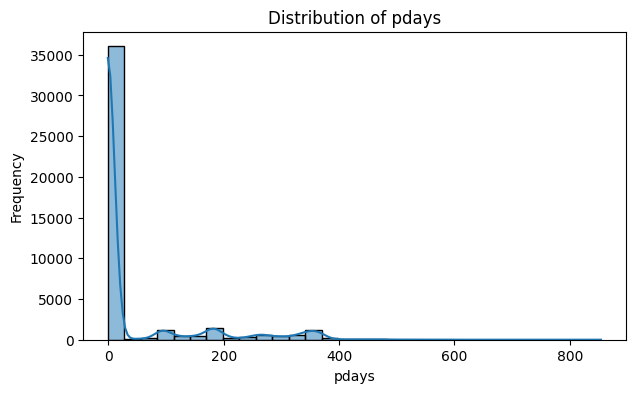

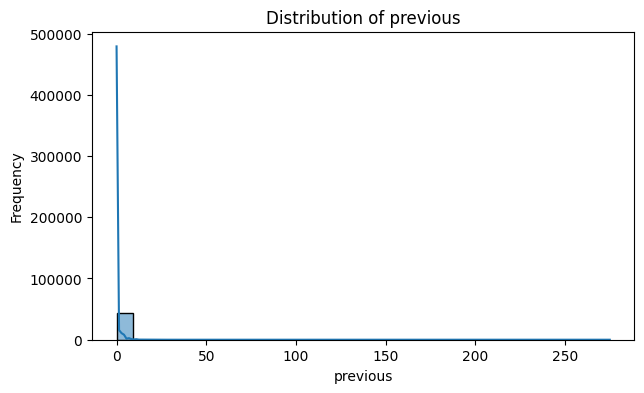

In [ ]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))

    sns.histplot(df[col], bins=30, kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.show()

In [ ]:
outlier_counts = {}

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_counts[col] = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

outlier_df = pd.DataFrame(
    outlier_counts.items(),
    columns=['Column', 'Outlier Count']
)

print(outlier_df)

     Column  Outlier Count
0       age            487
1   balance           4592
2  campaign           3005
3     pdays           8044
4  previous           8044


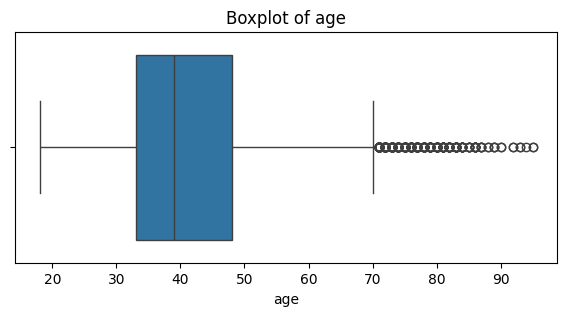

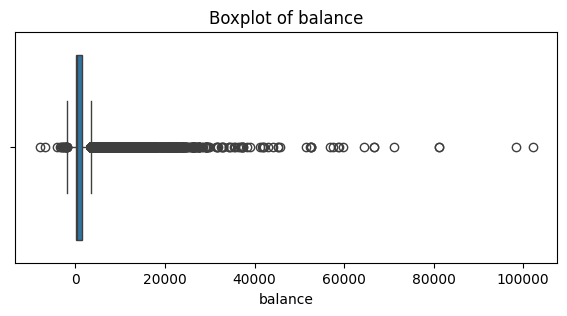

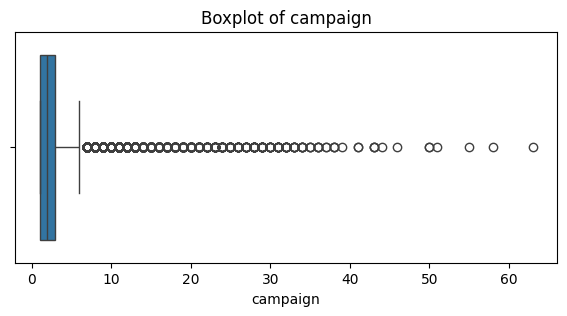

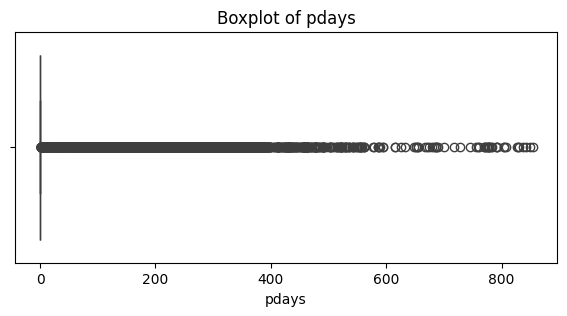

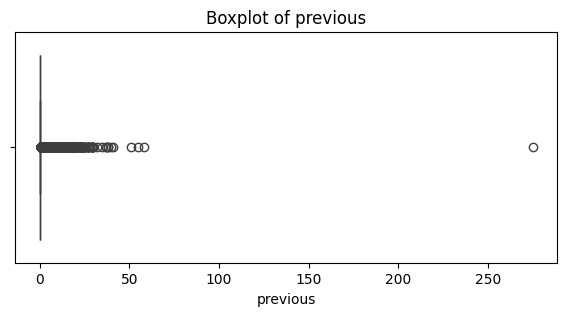

In [ ]:
for col in numerical_cols:
    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)

    plt.show()

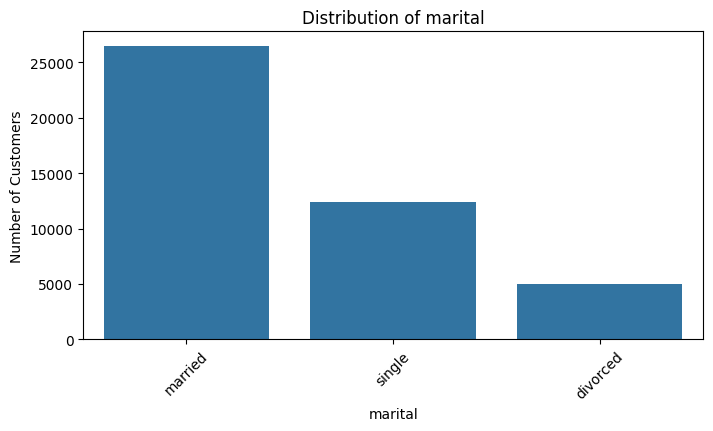

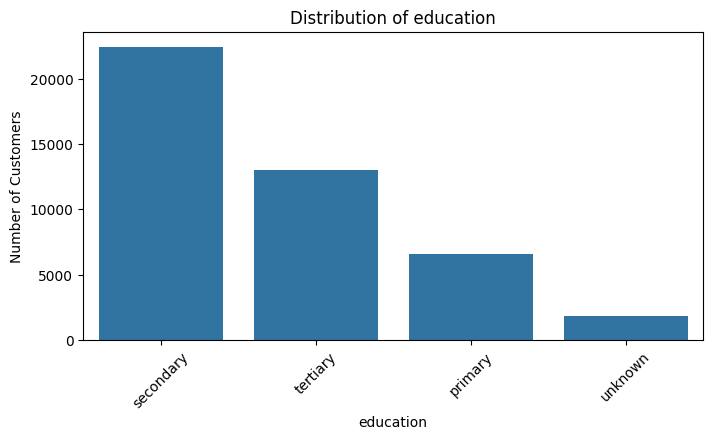

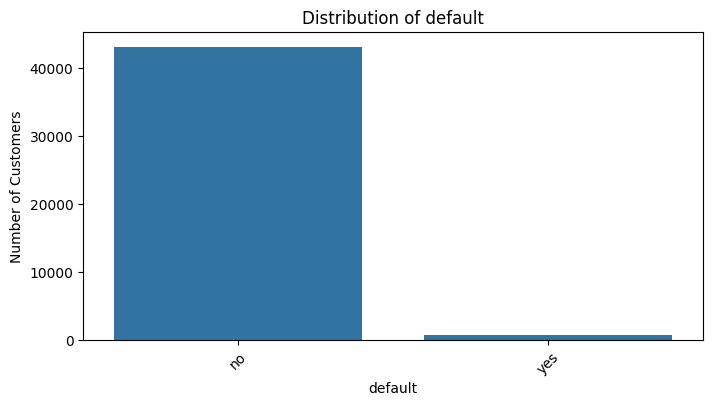

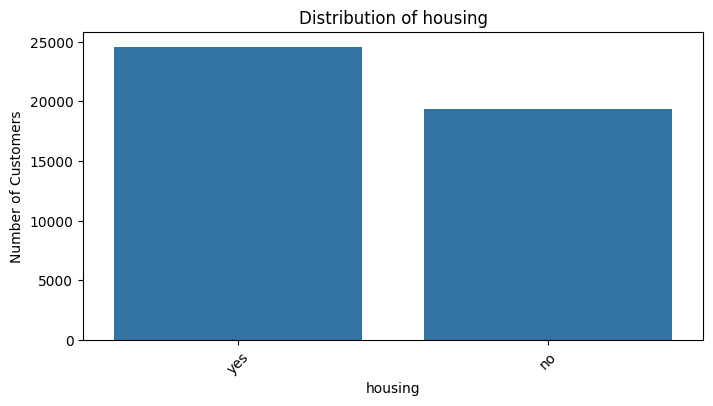

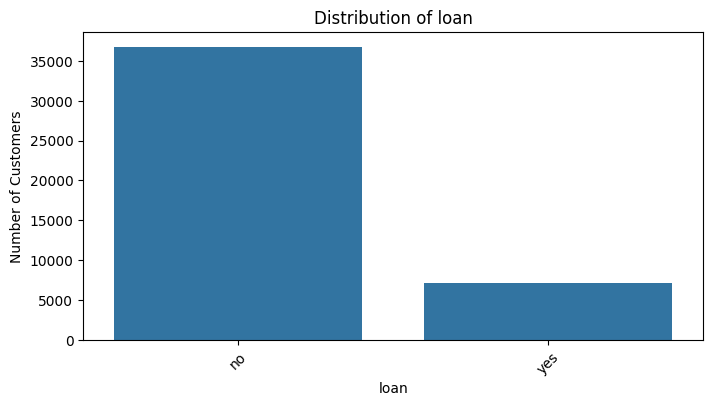

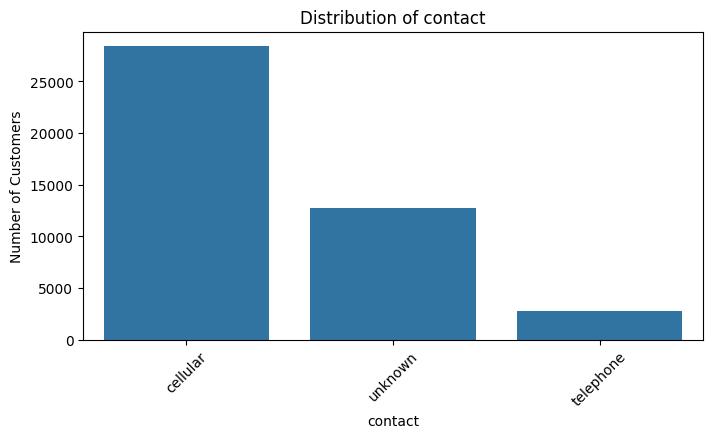

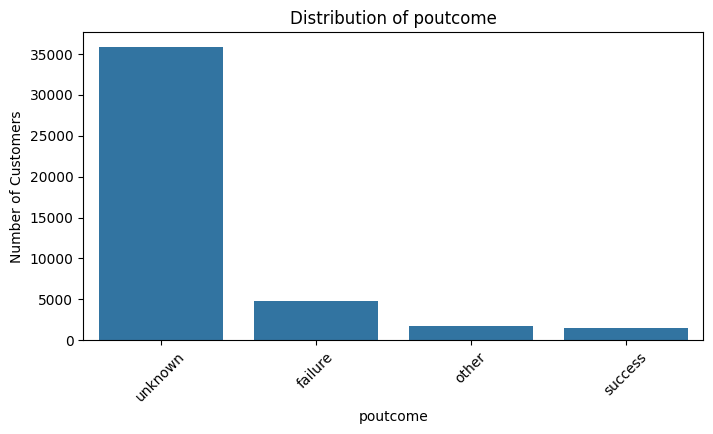

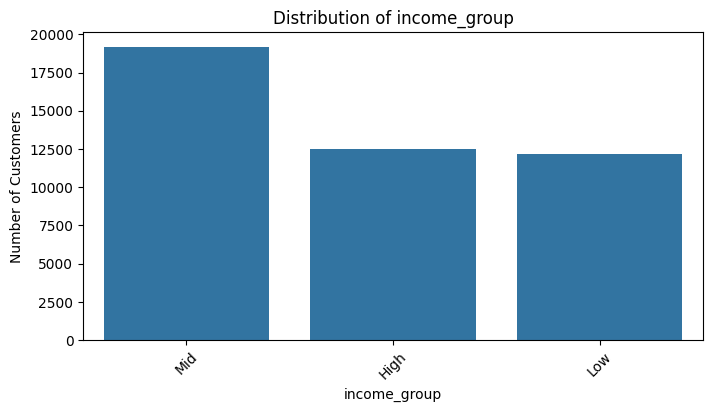

In [ ]:
for col in categorical_cols:
    plt.figure(figsize=(8, 4))

    sns.countplot(
        x=col,
        data=df,
        order=df[col].value_counts().index
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Customers')

    plt.xticks(rotation=45)
    plt.show()

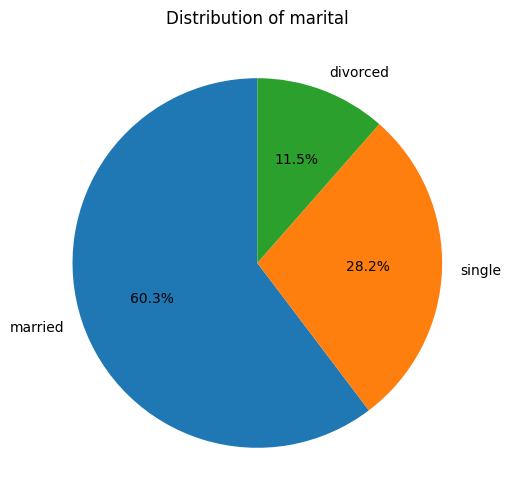

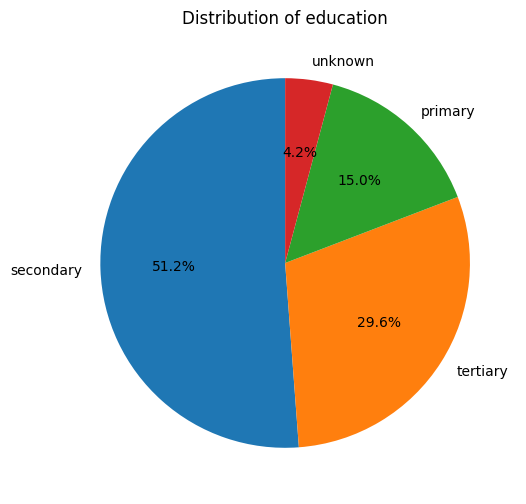

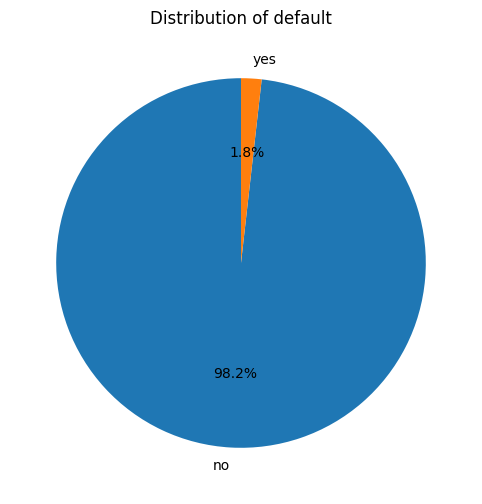

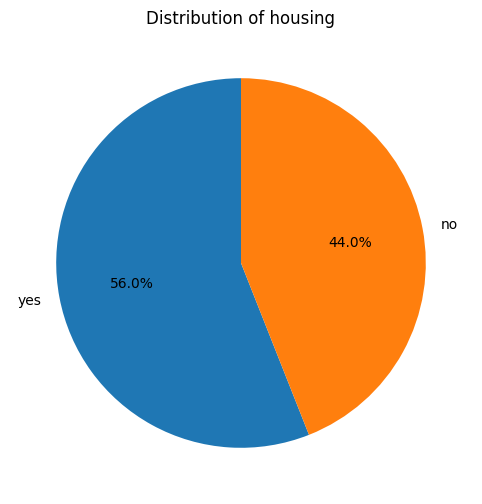

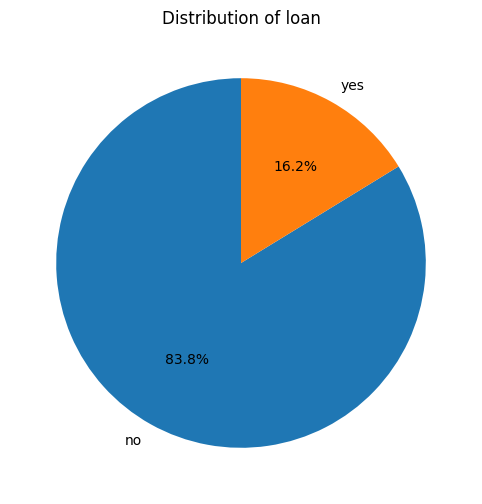

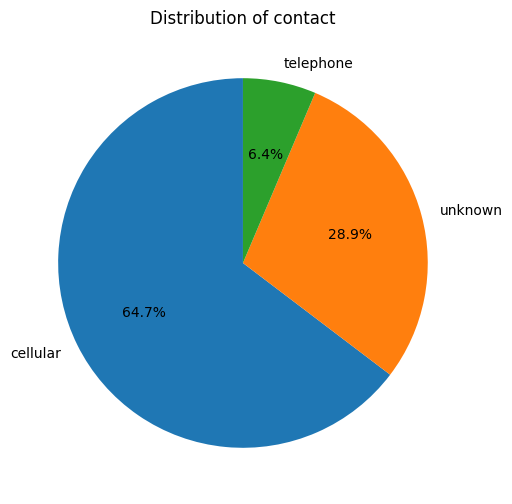

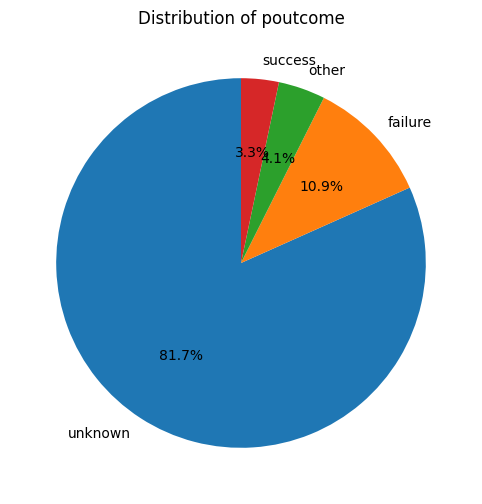

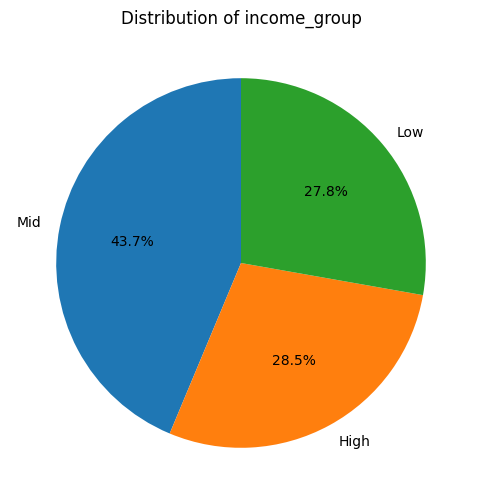

In [ ]:
for col in categorical_cols:
    plt.figure(figsize=(8, 6))

    counts = df[col].value_counts()

    plt.pie(
        counts,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=90
    )

    plt.title(f'Distribution of {col}')
    plt.show()

In [ ]:
for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts(normalize=True).mul(100).round(2))



marital
marital
married     60.31
single      28.22
divorced    11.47
Name: proportion, dtype: float64

education
education
secondary    51.18
tertiary     29.63
primary      15.02
unknown       4.16
Name: proportion, dtype: float64

default
default
no     98.21
yes     1.79
Name: proportion, dtype: float64

housing
housing
yes    56.0
no     44.0
Name: proportion, dtype: float64

loan
loan
no     83.75
yes    16.25
Name: proportion, dtype: float64

contact
contact
cellular     64.67
unknown      28.94
telephone     6.39
Name: proportion, dtype: float64

poutcome
poutcome
unknown    81.69
failure    10.91
other       4.11
success     3.30
Name: proportion, dtype: float64

income_group
income_group
Mid     43.70
High    28.52
Low     27.78
Name: proportion, dtype: float64


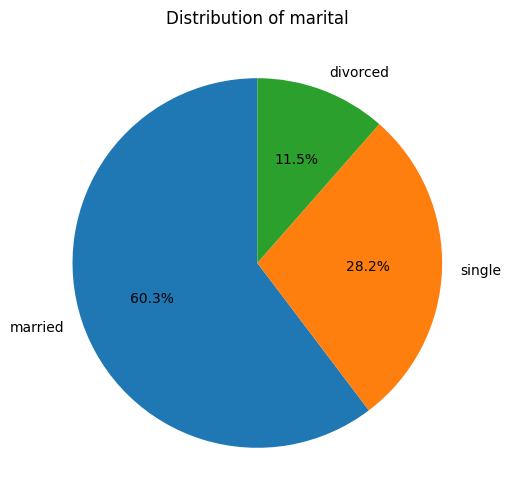

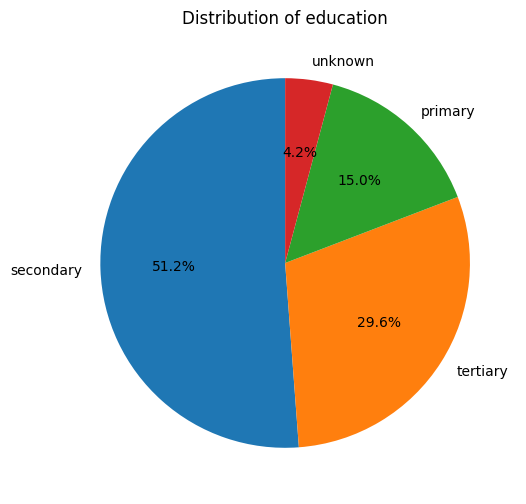

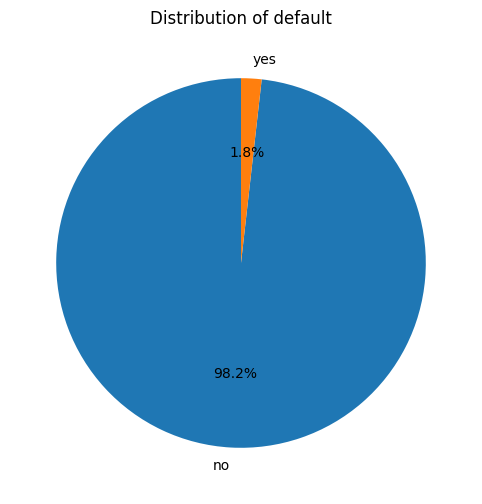

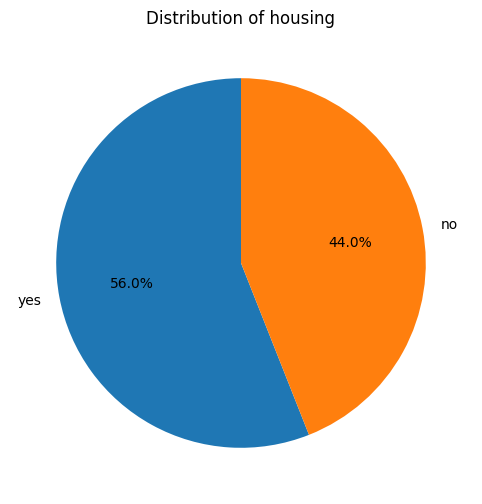

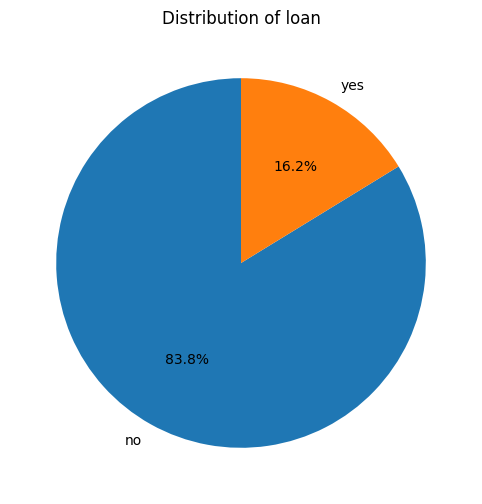

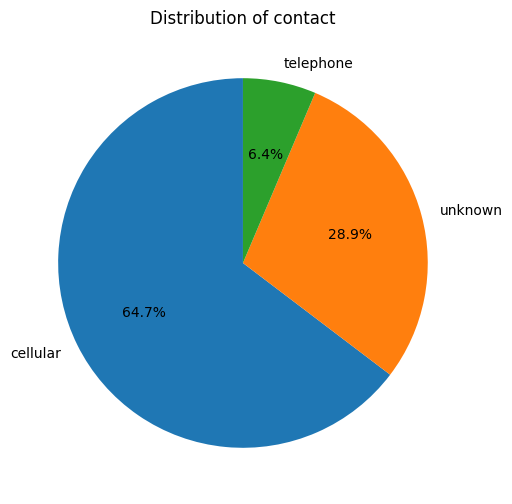

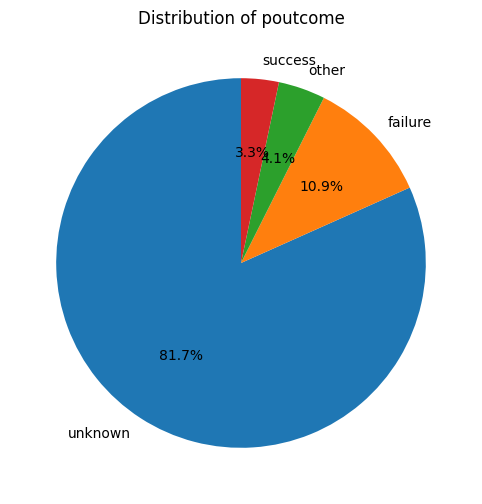

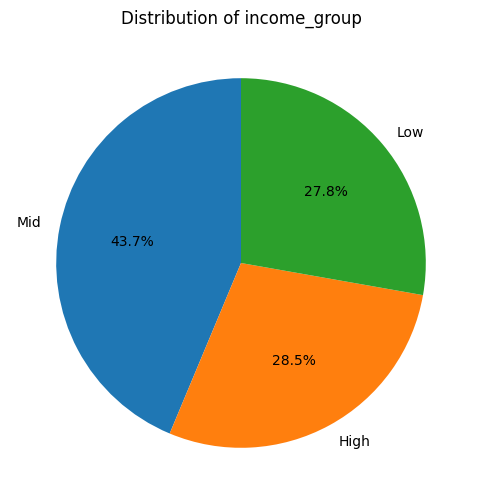

In [ ]:
for col in categorical_cols:
    plt.figure(figsize=(8, 6))

    counts = df[col].value_counts()

    plt.pie(
        counts,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=90
    )

    plt.title(f'Distribution of {col}')
    plt.show()

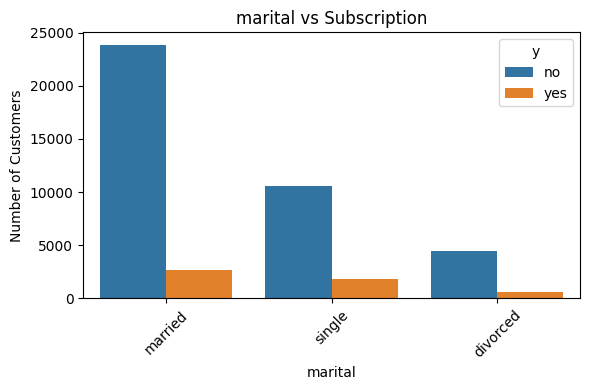

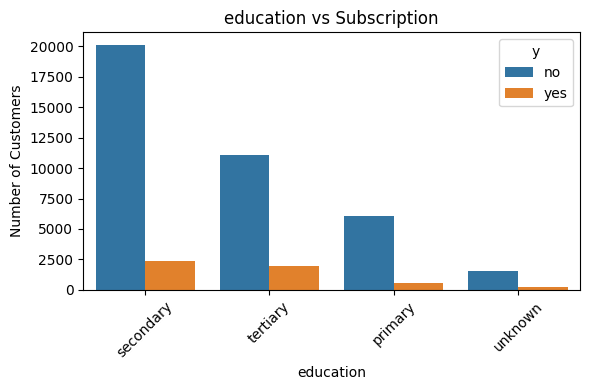

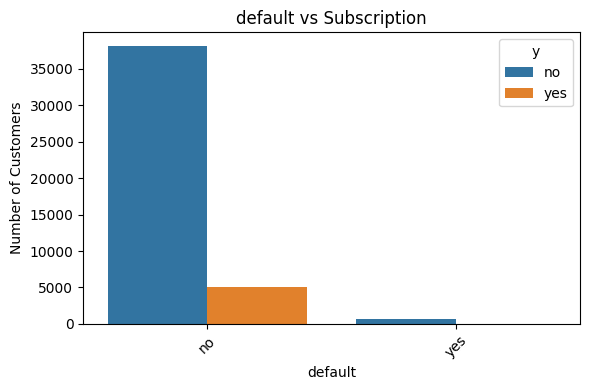

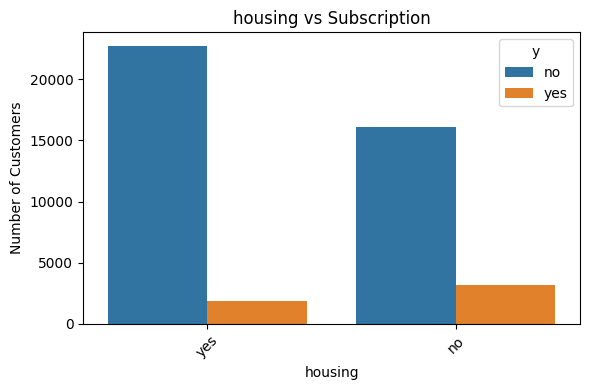

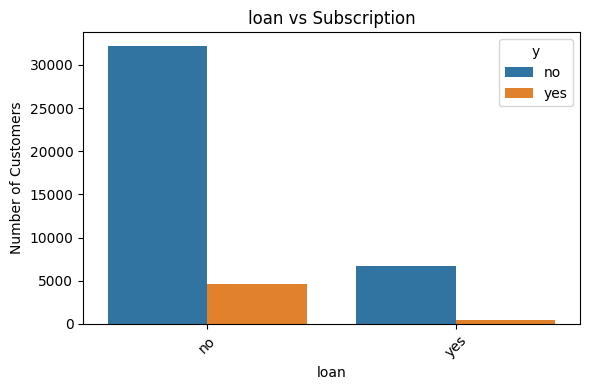

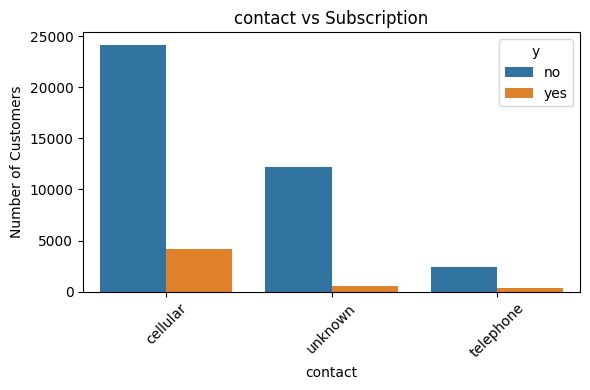

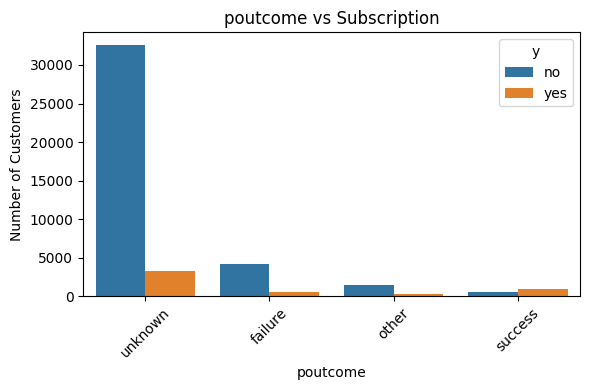

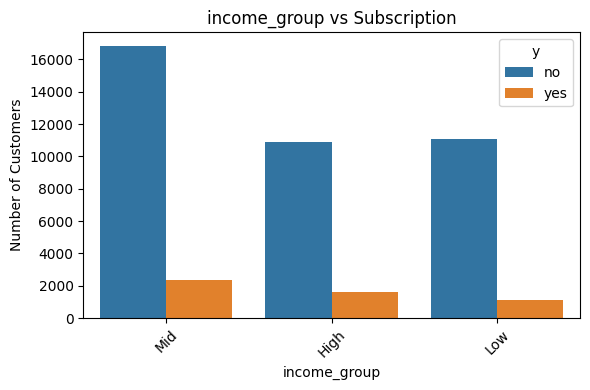

In [ ]:
for col in categorical_cols:

    plt.figure(figsize=(6, 4))

    order = df[col].value_counts().index

    sns.countplot(
        x=col,
        hue='y',
        data=df,
        order=order
    )

    plt.title(f'{col} vs Subscription')
    plt.xlabel(col)
    plt.ylabel('Number of Customers')

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
for col in categorical_cols:

    result = pd.crosstab(
        df[col],
        df['y'],
        normalize='index'
    ) * 100

    print(f"\n===== {col} =====")
    print(result.round(2))


===== marital =====
y            no    yes
marital               
divorced  88.19  11.81
married   89.96  10.04
single    85.20  14.80

===== education =====
y             no    yes
education              
primary    91.55   8.45
secondary  89.58  10.42
tertiary   85.09  14.91
unknown    86.43  13.57

===== default =====
y           no    yes
default              
no       88.32  11.68
yes      93.63   6.37

===== housing =====
y           no    yes
housing              
no       83.48  16.52
yes      92.29   7.71

===== loan =====
y        no    yes
loan              
no    87.46  12.54
yes   93.31   6.69

===== contact =====
y             no    yes
contact                
cellular   85.22  14.78
telephone  86.56  13.44
unknown    95.96   4.04

===== poutcome =====
y            no    yes
poutcome              
failure   87.60  12.40
other     83.42  16.58
success   35.87  64.13
unknown   90.89   9.11

===== income_group =====
y                no    yes
income_group              
High

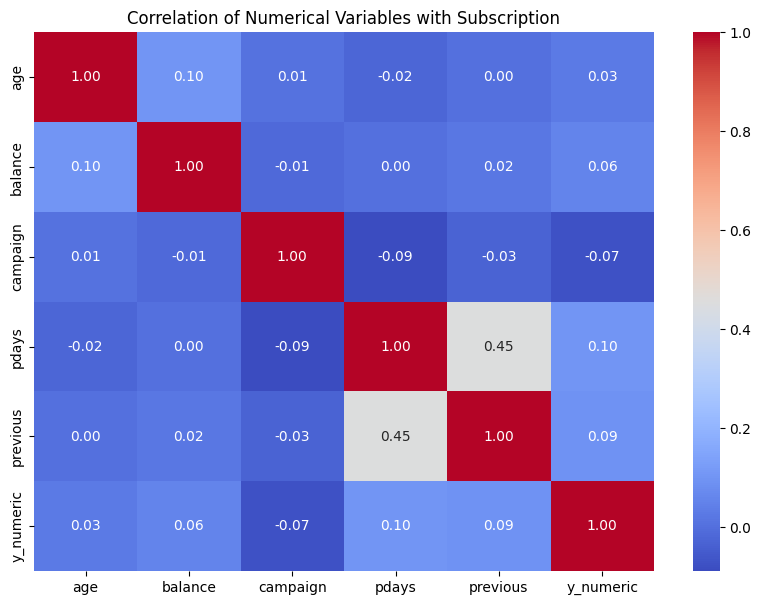

In [ ]:
df['y_numeric'] = df['y'].map({
    'no': 0,
    'yes': 1
})
correlation = df[numerical_cols + ['y_numeric']].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation of Numerical Variables with Subscription')

plt.show()

In [ ]:
df.drop('y_numeric', axis=1, inplace=True)

In [ ]:
# Count of each class
print(df['y'].value_counts())

# Percentage of each class
print(df['y'].value_counts(normalize=True) * 100)

y
no     38821
yes     5087
Name: count, dtype: int64
y
no     88.414412
yes    11.585588
Name: proportion, dtype: float64


# **Model building and Evaluation**

In [ ]:
df_encoded.head()

,age,default,balance,housing,loan,campaign,pdays,previous,y,income_group_Low,...,marital_married,marital_single,education_secondary,education_tertiary,education_unknown,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,1,-1,0,0,0,...,1,0,0,1,0,0,1,0,0,1
1,44,0,29,1,0,1,-1,0,0,0,...,0,1,1,0,0,0,1,0,0,1
2,33,0,2,1,1,1,-1,0,0,0,...,1,0,1,0,0,0,1,0,0,1
3,47,0,1506,1,0,1,-1,0,0,1,...,1,0,0,0,1,0,1,0,0,1
4,33,0,1,0,0,1,-1,0,0,1,...,0,1,0,0,1,0,1,0,0,1


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

In [ ]:
x = df_encoded.drop('y', axis=1)
y = df_encoded['y']

In [ ]:
test_sizes = [0.2, 0.25, 0.3, 0.4]
models = [
    LogisticRegression(class_weight='balanced',random_state=42),
    DecisionTreeClassifier(class_weight='balanced',random_state=42),
    RandomForestClassifier(class_weight='balanced',random_state=42),
    GradientBoostingClassifier(random_state=42),
    XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    eval_metric='logloss')
    ]

In [ ]:
import pandas as pd

print("Before SMOTE:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())
print((y_train_resampled.value_counts(normalize=True) * 100).round(2))

Before SMOTE:
y
0    23292
1     3052
Name: count, dtype: int64
y
0    88.41
1    11.59
Name: proportion, dtype: float64

After SMOTE:
y
0    23292
1    23292
Name: count, dtype: int64
y
0    50.0
1    50.0
Name: proportion, dtype: float64


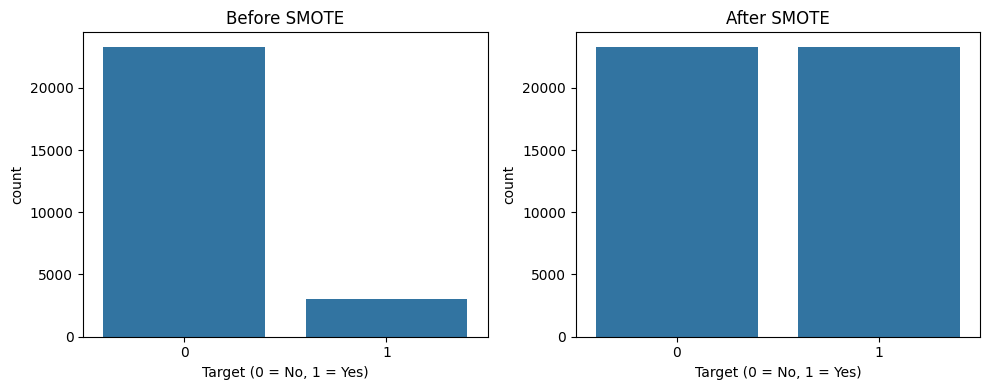

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Target (0 = No, 1 = Yes)")

sns.countplot(x=y_train_resampled, ax=axes[1])
axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Target (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

In [ ]:
from imblearn.over_sampling import SMOTE
results = []

for test_size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(
        x, y, test_size=test_size, random_state=42, stratify=y
    )
    smote = SMOTE(random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

    # Scale the features (X) only
    scaler = StandardScaler()
    X_train_resampled_scaled = scaler.fit_transform(X_train_resampled)
    X_test_scaled = scaler.transform(X_test)

    for model in models:
        # Train on the resampled and scaled training features
        model.fit(X_train_resampled_scaled, y_train_resampled)
        # Predict on scaled test features
        pred = model.predict(X_test_scaled)

        results.append({
            'Test Size': test_size,
            'Train Size': 1 - test_size,
            'Model': model.__class__.__name__,
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1 Score': f1_score(y_test, pred),
            'Accuracy': accuracy_score(y_test, pred)
        })

results_df = pd.DataFrame(results)
results_df

,Test Size,Train Size,Model,Precision,Recall,F1 Score,Accuracy
0,0.20,0.80,LogisticRegression,0.256935,0.382498,0.307388,0.800387
1,0.20,0.80,DecisionTreeClassifier,0.222880,0.333333,0.267139,0.788203
2,0.20,0.80,RandomForestClassifier,0.307832,0.332350,0.319622,0.836142
3,0.20,0.80,GradientBoostingClassifier,0.302210,0.416912,0.350413,0.820997
4,0.20,0.80,XGBClassifier,0.312549,0.394297,0.348696,0.829424
5,0.25,0.75,LogisticRegression,0.250806,0.367138,0.298022,0.799581
6,0.25,0.75,DecisionTreeClassifier,0.224119,0.319969,0.263601,0.792840
7,0.25,0.75,RandomForestClassifier,0.298221,0.329403,0.313037,0.832468
8,0.25,0.75,GradientBoostingClassifier,0.297909,0.403302,0.342685,0.820716
9,0.25,0.75,XGBClassifier,0.312856,0.388365,0.346545,0.830281


In [ ]:
results_df['Accuracy'].idxmax()


17

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Best model based on Accuracy
best_model = RandomForestClassifier(random_state=42)

best_model.fit(X_train_resampled, y_train_resampled)

# Prediction
y_pred = best_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Best Model: Gradient Boosting Classifier")
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best Model: Gradient Boosting Classifier
Accuracy: 0.8405
Accuracy: 84.05%

Confusion Matrix:
[[14086  1443]
 [ 1358   677]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91     15529
           1       0.32      0.33      0.33      2035

    accuracy                           0.84     17564
   macro avg       0.62      0.62      0.62     17564
weighted avg       0.84      0.84      0.84     17564



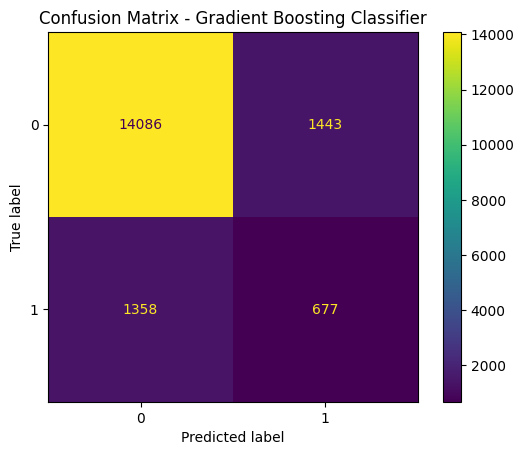

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("Confusion Matrix - Gradient Boosting Classifier")
plt.show()

**Conclusion:**

# **ANN**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD

In [ ]:
neurons = [(8,4), (16,8), (32,16)]
dropouts = [0.2]
batch_sizes = [32, 64]
optimizers = ['Adam', 'SGD']

In [ ]:
def create_ann(neurons1, neurons2, dropout, learning_rate, optimizer_name):

    # Select optimizer
    if optimizer_name == 'Adam':
        optimizer = Adam(learning_rate=learning_rate)

    else:
        optimizer = SGD(learning_rate=learning_rate)

    # Create model
    model = Sequential([

        Input(shape=(X_train_scaled.shape[1],)),

        Dense(neurons1, activation='relu'),
        Dropout(dropout),

        Dense(neurons2, activation='relu'),
        Dropout(dropout),

        Dense(1, activation='sigmoid')
    ])

    # Compile model
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled, y_train
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

ann_results = []

for i in neurons:
    for j in dropouts:
        for l in batch_sizes:
                for opt in optimizers:

                    # Create model
                    model = create_ann(
                        neurons1=i[0],
                        neurons2=i[1],
                        learning_rate=0.001,
                        dropout=j,
                        optimizer_name=opt
                    )

                    # Early stopping
                    early_stop = EarlyStopping(
                        monitor='val_loss',
                        patience=5,
                        restore_best_weights=True
                    )

                    # Train model
                    history = model.fit(
                        X_train_scaled,
                        y_train,
                        epochs=100,
                        batch_size=l,
                        validation_split=0.20,
                        callbacks=[early_stop],
                        verbose=0
                    )

                    # Predict probabilities
                    ann_pred_prob = model.predict(
                        X_test_scaled,
                        verbose=0
                    )

                    # Convert probabilities to classes
                    ann_pred = (
                        ann_pred_prob >= 0.5
                    ).astype(int).flatten()

                    # Evaluation metrics
                    accuracy = accuracy_score(
                        y_test,
                        ann_pred
                    )

                    precision = precision_score(
                        y_test,
                        ann_pred,
                        zero_division=0
                    )

                    recall = recall_score(
                        y_test,
                        ann_pred,
                        zero_division=0
                    )

                    f1 = f1_score(
                        y_test,
                        ann_pred,
                        zero_division=0
                    )

                    # Store results
                    ann_results.append({

                        'Neurons': f'{i[0]}-{i[1]}',
                        'Dropout': j,
                        'Batch Size': l,
                        'Optimizer': opt,
                        'Epochs': len(history.history['loss']),
                        'Accuracy': accuracy * 100,
                        'Precision': precision * 100,
                        'Recall': recall * 100,
                        'F1 Score': f1 * 100,
                        'History': history.history
                    })

In [ ]:
best_ann = ann_results_df.loc[
    ann_results_df['F1 Score'].idxmax()
]

best_ann

In [ ]:
best_ann_accuracy = ann_results_df.loc[
    ann_results_df['Accuracy'].idxmax()
]

best_ann_accuracy

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    best_history['loss'],
    label='Training Loss'
)

plt.plot(
    best_history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    best_history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    best_history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')

plt.legend()
plt.show()